In [11]:
import numpy as np
from collections import Counter

def entropy(y):
    hist = np.bincount(y)
    ps = hist / len(y)
    return -np.sum([p * np.log2(p) for p in ps if p > 0])        

class node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
    def is_leaf_node(self): 
        return self.value is not None

class DecisionTree:
    def __init__(self,min_samples_split=2, max_depth=100, n_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.n_features = n_features
        self.root = None
        
    def fit(self, X,y):
        self.n_features = X.shape[1] if self.n_features is None else min(self.n_features, X.shape[1])
        self.root = self._grow_tree(X,y)
    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))
        
        if (depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return node(value=leaf_value)
        #greed search
        feat_idxs = np.random.choice(n_features, self.n_features, replace=False)
        
        best_feat, best_thresh = self._best_criteria(X,y,feat_idxs)
        
        left_idxs, right_idxs = self._split(X[:, best_feat], best_thresh)
        left = self._grow_tree(X[left_idxs,:], y[left_idxs], depth+1)
        right = self._grow_tree(X[right_idxs,:], y[right_idxs], depth+1)
        return node(best_feat, best_thresh, left, right)    
    def predict(self,x):
        return np.array([self._traverse_tree(xi, self.root) for xi in x])
    def _traverse_tree(self, x, node):  
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)
    def _most_common_label(self,y):
        counter = Counter(y)
        most_common = counter.most_common(1)[0][0]
        return most_common 
    # function for the greedy search of the best split  
    def _best_criteria(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_thresh = None, None
        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            for threshold in thresholds:
                gain = self._information_gain(y, X_column, threshold)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = threshold
        return split_idx, split_thresh     
    def _information_gain(self, y, X_column, split_thresh):
        # parent entropy
        parent_entropy = entropy(y)
        # generating the split
        left_idxs, right_idxs = self._split(X_column, split_thresh)
        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0
        
        # compute the weighted avg. of the loss for the children
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = entropy(y[left_idxs]), entropy(y[right_idxs])
        child_entropy = (n_l/n) * e_l + (n_r/n) * e_r
        
        # information gain is difference in loss before vs. after split
        ig = parent_entropy - child_entropy
        return ig  
    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs  

# TESTING THE DECISION TREE

In [12]:
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split

data = datasets.load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.3, random_state=42
)

tree = DecisionTree(max_depth=5)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)
print("Test accuracy:", np.mean(y_pred == y_test))

Test accuracy: 0.9532163742690059


## Plot 1: the learned tree (top 3 levels)

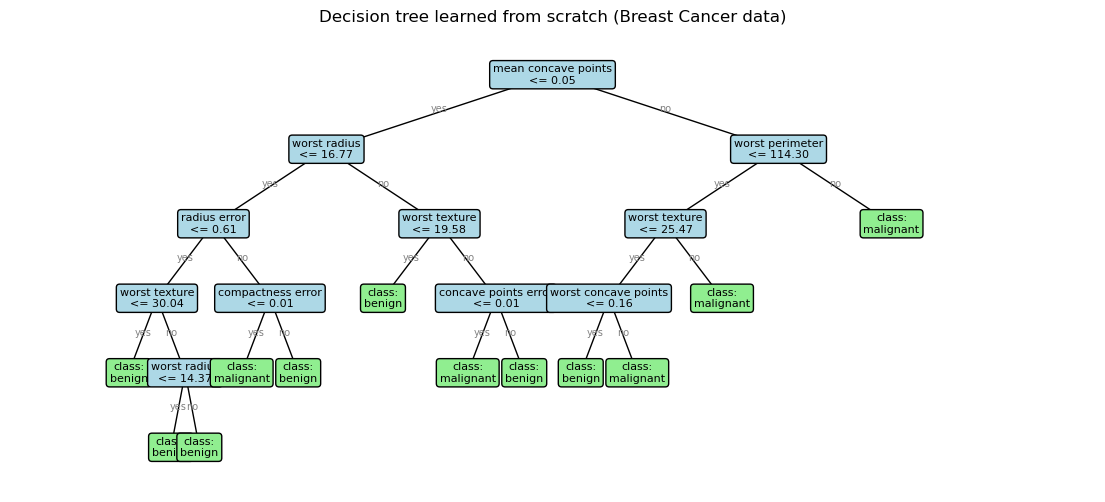

In [16]:
def draw_tree(root, feature_names, class_names, max_depth=3):
    fig, ax = plt.subplots(figsize=(14, 6))
    ax.axis("off")
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-max_depth - 0.6, 0.6)

    def draw(n, x, y, dx, depth):
        if n.is_leaf_node():
            ax.text(x, y, f"class:\n{class_names[n.value]}", ha="center", va="center",
                    fontsize=8, bbox=dict(boxstyle="round", fc="lightgreen", ec="k"))
            return
        if depth == max_depth:
            ax.text(x, y, "...", ha="center", va="center", fontsize=12)
            return
        ax.text(x, y, f"{feature_names[n.feature]}\n<= {n.threshold:.2f}",
                ha="center", va="center", fontsize=8, zorder=3,
                bbox=dict(boxstyle="round", fc="lightblue", ec="k"))
        for child, cx, lab in ((n.left, x - dx, "yes"), (n.right, x + dx, "no")):
            ax.plot([x, cx], [y, y - 1], "k-", lw=1, zorder=1)
            ax.text((x + cx) / 2, y - 0.5, lab, fontsize=7, ha="center", color="gray")
            draw(child, cx, y - 1, dx / 2, depth + 1)

    draw(root, 0, 0, 0.5, 0)
    ax.set_title("Decision tree learned from scratch (Breast Cancer data)")
    plt.show()

draw_tree(tree.root, data.feature_names, data.target_names, max_depth=5)

## Plot 2: decision regions on 2 features

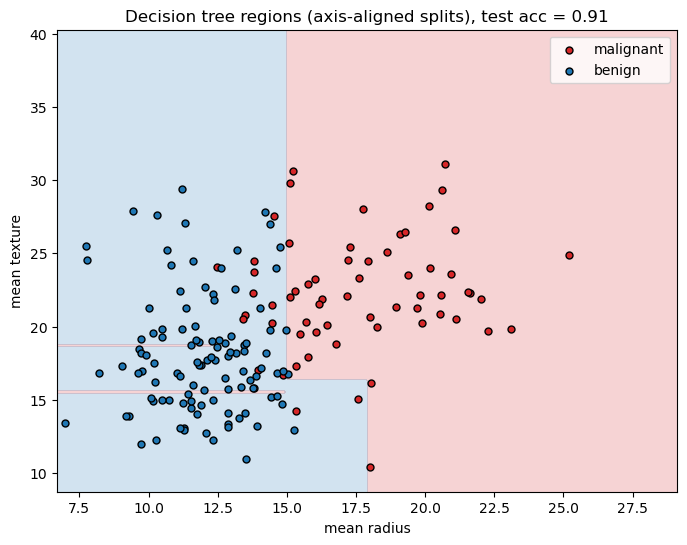

In [14]:
f1, f2 = 0, 1   # mean radius, mean texture
X2_train, X2_test = X_train[:, [f1, f2]], X_test[:, [f1, f2]]

tree2 = DecisionTree(max_depth=4)
tree2.fit(X2_train, y_train)
acc2 = np.mean(tree2.predict(X2_test) == y_test)

xx, yy = np.meshgrid(
    np.linspace(X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1, 200),
    np.linspace(X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1, 200),
)
Z = tree2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=["tab:red", "tab:blue"], alpha=0.2)
for cls, color in ((0, "tab:red"), (1, "tab:blue")):
    m = y_test == cls
    ax.scatter(X2_test[m, 0], X2_test[m, 1], c=color, s=25, edgecolors="k",
               label=data.target_names[cls])
ax.set_xlabel(data.feature_names[f1]); ax.set_ylabel(data.feature_names[f2])
ax.set_title(f"Decision tree regions (axis-aligned splits), test acc = {acc2:.2f}")
ax.legend()
plt.show()

## Plot 3: accuracy vs. max_depth (overfitting check)

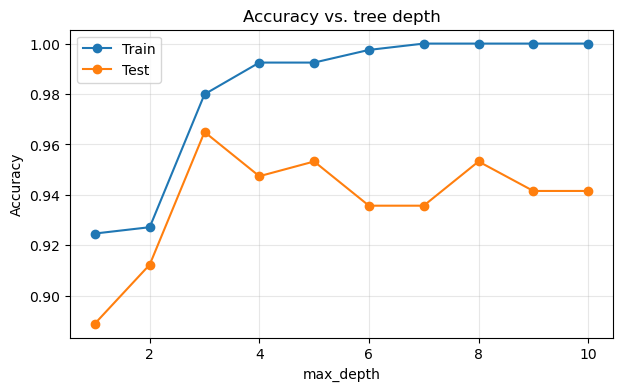

In [18]:
depths = range(1, 11)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTree(max_depth=d)
    t.fit(X_train, y_train)
    train_acc.append(np.mean(t.predict(X_train) == y_train))
    test_acc.append(np.mean(t.predict(X_test) == y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, "o-", label="Train")
plt.plot(depths, test_acc, "o-", label="Test")
plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.title("Accuracy vs. tree depth")
plt.legend(); plt.grid(alpha=0.3)
plt.show()